# Module project: look inside a CNN, then fool it

This notebook builds the whole project, file by file, exactly as the lesson does. Run it from top to bottom in Google Colab or Jupyter: each `%%writefile` cell writes one file of the project, and each `!python` cell runs it. Then try the ideas under **Make it yours**.

Better still: type the files yourself in your own editor, and use this notebook to check your work.

## Attachments and data

- **Notebook**: `project-2-cnn-under-the-hood.ipynb`, attached to this lesson and saved on your device with the course. It builds and runs the whole project. Open it in one click in Google Colab (free, nothing to install): [Open in Colab](https://colab.research.google.com/github/mahmoudyosrimahmoud13/inpace-library/blob/main/courses/bishop-dl-3-architectures/files/project-2-cnn-under-the-hood.ipynb). Or open the saved copy on your device with Jupyter or VS Code.
- **Finished code**: the `projects/cnn-under-the-hood` folder in the course files, to check your work.
- **Data**: CIFAR-10 (University of Toronto; Hugging Face: uoft-cs/cifar10). Source: [https://huggingface.co/datasets/uoft-cs/cifar10](https://huggingface.co/datasets/uoft-cs/cifar10) · about: [https://www.cs.toronto.edu/~kriz/cifar.html](https://www.cs.toronto.edu/~kriz/cifar.html) · licence: free for research and teaching (see the CIFAR page). `data.py` downloads it the first time you run it and keeps it in `data/`: `cifar10_test.npz`, `cifar10_train.npz`, 176.2 MB.

In [ ]:
%pip install -q torch pandas pyarrow pillow matplotlib

Section 10.3 asks two questions about a trained network: **what has it learned?** and **how robust is it?** In this
project you answer both for the CIFAR-10 network you built in the last module. You'll draw its filters, compute saliency
maps that show which pixels drive each prediction, and then turn the same gradients into a weapon: an **adversarial
attack** that changes every pixel by an amount too small to see, and makes the network wrong almost every time.

Adversarial robustness is a real concern for self-driving cars, face recognition and content filters, and showing you
can attack a model (and explain why it works) is a strong addition to a portfolio. The notebook attached above builds
and runs the whole project; the reference code is in the course files under `projects/cnn-under-the-hood`.

## What you'll build

```mermaid
flowchart LR
    A[your trained CNN<br/>from cifar-cnn] --> B[inspect_cnn.py<br/>filters +<br/>saliency maps]
    A --> C[attack.py<br/>FGSM: one gradient step<br/>against the network]
    C --> D[accuracy vs<br/>size of the change]
```

## Set up the project

Start from a copy of your `cifar-cnn` project, so `data.py`, `model.py` and `train.py` are already there, and copy the
trained `cnn.pt` too (or train it again).

```bash
cp -r cifar-cnn cnn-under-the-hood && cd cnn-under-the-hood
source .venv/bin/activate     # or create a new one and pip install -r requirements.txt
```

```text
cnn-under-the-hood/
    .gitignore
    README.md
    attack.py
    cnn.pt
    data.py
    inspect_cnn.py
    model.py
    requirements.txt
    train.py
```

In [ ]:
%%writefile requirements.txt
torch
pandas
pyarrow
pillow
matplotlib

Writing requirements.txt


In [ ]:
%%writefile .gitignore
data/
outputs/
__pycache__/
*.pt
.venv/

Writing .gitignore


In [ ]:
%%writefile data.py
"""CIFAR-10: 60,000 colour photos, 32x32 pixels, 10 classes (Hugging Face hub)."""
from pathlib import Path
import io
import numpy as np
import pandas as pd
import torch
from PIL import Image

URL = "https://huggingface.co/api/datasets/uoft-cs/cifar10/parquet/plain_text/{}/0.parquet"
CLASSES = ["airplane", "car", "bird", "cat", "deer", "dog", "frog", "horse", "ship", "truck"]
MEAN = torch.tensor([0.491, 0.482, 0.447]).view(1, 3, 1, 1)
STD = torch.tensor([0.247, 0.243, 0.262]).view(1, 3, 1, 1)


def load(split):
    """split: 'train' (50,000) or 'test' (10,000). Returns uint8 images (N, 3, 32, 32) and labels."""
    cache = Path(f"data/cifar10_{split}.npz")
    if not cache.exists():
        cache.parent.mkdir(exist_ok=True)
        table = pd.read_parquet(URL.format(split))
        X = np.stack([np.array(Image.open(io.BytesIO(img["bytes"])).convert("RGB")) for img in table["img"]])
        np.savez(cache, X=X.transpose(0, 3, 1, 2), y=table["label"].values)
    d = np.load(cache)
    return torch.from_numpy(d["X"]), torch.from_numpy(d["y"]).long()


def normalize(x_uint8):
    """uint8 images -> floats with mean 0 and standard deviation 1 per colour channel (section 7.4.1)."""
    return (x_uint8.float() / 255 - MEAN) / STD


def load_splits():
    X, y = load("train")
    order = torch.randperm(len(X), generator=torch.Generator().manual_seed(0))
    val, train = order[:5000], order[5000:]
    return (X[train], y[train]), (X[val], y[val]), load("test")


if __name__ == "__main__":
    (xtr, ytr), (xva, yva), (xte, yte) = load_splits()
    print(f"train {tuple(xtr.shape)}, validation {len(xva)}, test {len(xte)}")
    print("per class in training:", torch.bincount(ytr).tolist())

Writing data.py


In [ ]:
%%writefile model.py
"""A small convolutional network (Bishop, sections 10.2.6 to 10.2.8): stacks of 3x3 convolutions, pooling, then a classifier."""
from torch import nn


def block(c_in, c_out):
    return nn.Sequential(nn.Conv2d(c_in, c_out, 3, padding=1), nn.BatchNorm2d(c_out), nn.ReLU(),
                         nn.Conv2d(c_out, c_out, 3, padding=1), nn.BatchNorm2d(c_out), nn.ReLU(),
                         nn.MaxPool2d(2))                       # 32x32 -> 16x16 -> 8x8 -> 4x4


class SmallCNN(nn.Module):
    def __init__(self, width=32, n_classes=10):
        super().__init__()
        self.features = nn.Sequential(block(3, width), block(width, 2 * width), block(2 * width, 4 * width))
        self.classifier = nn.Sequential(nn.Flatten(), nn.Dropout(0.3), nn.Linear(4 * width * 4 * 4, n_classes))

    def forward(self, x):
        return self.classifier(self.features(x))

Writing model.py


In [ ]:
%%writefile train.py
"""Train the CNN on CIFAR-10. On a laptop CPU an epoch takes about a minute; on a GPU (or free Colab), seconds.
Example: python train.py --epochs 6"""
import argparse
import torch
import torch.nn.functional as F
from data import load_splits, normalize
from model import SmallCNN


def augment(x):
    """Random horizontal flips and random crops of 4-pixel padded images (section 9.1.3).
    A car seen in a mirror is still a car, so here, unlike Fashion-MNIST, flips are safe."""
    flip = torch.rand(len(x)) < 0.5
    x = torch.where(flip[:, None, None, None], x.flip(3), x)
    padded = F.pad(x, (4, 4, 4, 4), mode="reflect")
    i, j = torch.randint(0, 9, (2,))
    return padded[:, :, i:i + 32, j:j + 32]                     # one random crop per mini-batch, for speed


def evaluate(model, x, y, batch=1000):
    model.eval()
    with torch.no_grad():
        guesses = torch.cat([model(normalize(x[i:i + batch])).argmax(1) for i in range(0, len(x), batch)])
    return (guesses == y).float().mean().item()


if __name__ == "__main__":
    ap = argparse.ArgumentParser()
    ap.add_argument("--epochs", type=int, default=6)
    ap.add_argument("--width", type=int, default=16)
    ap.add_argument("--no-augment", action="store_true")
    args = ap.parse_args()
    torch.manual_seed(0)
    (xtr, ytr), (xva, yva), _ = load_splits()
    model = SmallCNN(args.width)
    print(f"{sum(p.numel() for p in model.parameters()):,} parameters")
    steps = args.epochs * (len(xtr) // 128)
    opt = torch.optim.AdamW(model.parameters(), lr=3e-3, weight_decay=5e-4)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=3e-3, total_steps=steps)
    for epoch in range(1, args.epochs + 1):
        model.train()
        order = torch.randperm(len(xtr))
        for start in range(0, len(xtr) - 127, 128):
            idx = order[start:start + 128]
            x = normalize(xtr[idx])
            if not args.no_augment:
                x = augment(x)
            loss = F.cross_entropy(model(x), ytr[idx])
            opt.zero_grad(); loss.backward(); opt.step(); sched.step()
        print(f"epoch {epoch}: last loss {loss.item():.3f}, validation accuracy {evaluate(model, xva, yva):.3f}")
    torch.save({"width": args.width, "state": model.state_dict()}, "cnn.pt")

Writing train.py


In [ ]:
!python train.py --epochs 6

82,778 parameters
epoch 1: last loss 1.300, validation accuracy 0.519
epoch 2: last loss 0.917, validation accuracy 0.637
epoch 3: last loss 0.852, validation accuracy 0.692
epoch 4: last loss 0.873, validation accuracy 0.735
epoch 5: last loss 0.710, validation accuracy 0.790
epoch 6: last loss 0.598, validation accuracy 0.801


## Step 1: filters and saliency

**Filters** (section 10.3.2). The first layer has 16 filters, each a 3 × 3 patch with 3 colour channels. We rescale each
one to show its colours.

**Saliency maps** (section 10.3.3). Take the score of the predicted class, and ask: if this pixel changed a little, how
much would the score change? That's the gradient of the score with respect to the input pixels, and autograd gives it in
one backward pass: the same backpropagation as training, but stopping at the **image** instead of the weights.

In [ ]:
%%writefile inspect_cnn.py
"""Look inside the trained CNN (Bishop, section 10.3): its first-layer filters, and saliency maps
showing which pixels decided each prediction."""
from pathlib import Path
import torch
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from data import load, normalize, CLASSES
from model import SmallCNN

saved = torch.load("cnn.pt")
model = SmallCNN(saved["width"]); model.load_state_dict(saved["state"]); model.eval()
Path("outputs").mkdir(exist_ok=True)

# 1. First-layer filters (section 10.3.2): each is a 3x3 colour patch the network slides over the image
W = model.features[0][0].weight.detach()                     # (width, 3, 3, 3)
fig, axes = plt.subplots(2, W.shape[0] // 2, figsize=(W.shape[0] // 2, 2.2))
for w, ax in zip(W, axes.flat):
    img = (w - w.min()) / (w.max() - w.min())
    ax.imshow(img.permute(1, 2, 0)); ax.axis("off")
fig.suptitle("first-layer filters, scaled to show their colours"); fig.tight_layout()
fig.savefig("outputs/filters.png", dpi=110)
print(f"saved outputs/filters.png ({W.shape[0]} filters of 3x3 pixels x 3 colours)")

# 2. Saliency maps (section 10.3.3): how much would each pixel change the score of the predicted class?
X, y = load("test")
idx = torch.arange(8)
x = normalize(X[idx]).requires_grad_(True)
scores = model(x)
pred = scores.argmax(1)
scores[torch.arange(len(idx)), pred].sum().backward()
saliency = x.grad.abs().amax(1)                              # strongest colour channel per pixel
fig, axes = plt.subplots(2, 8, figsize=(12, 3.4))
for k in range(8):
    axes[0, k].imshow(X[idx[k]].permute(1, 2, 0)); axes[0, k].axis("off")
    axes[0, k].set_title(f"{CLASSES[pred[k]]}" + ("" if pred[k] == y[idx[k]] else f"\n(is {CLASSES[y[idx[k]]]})"), fontsize=8)
    axes[1, k].imshow(saliency[k], cmap="hot"); axes[1, k].axis("off")
fig.suptitle("prediction (top) and saliency: pixels that most affect it (bottom)"); fig.tight_layout()
fig.savefig("outputs/saliency.png", dpi=110)
print("saved outputs/saliency.png")
for k in range(8):
    print(f"image {k}: true {CLASSES[y[idx[k]]]:8s} predicted {CLASSES[pred[k]]}")

Writing inspect_cnn.py


In [ ]:
!python inspect_cnn.py

saved outputs/filters.png (16 filters of 3x3 pixels x 3 colours)
saved outputs/saliency.png
image 0: true cat      predicted cat
image 1: true ship     predicted ship
image 2: true ship     predicted ship
image 3: true airplane predicted ship
image 4: true frog     predicted frog
image 5: true frog     predicted frog
image 6: true car      predicted car
image 7: true frog     predicted deer


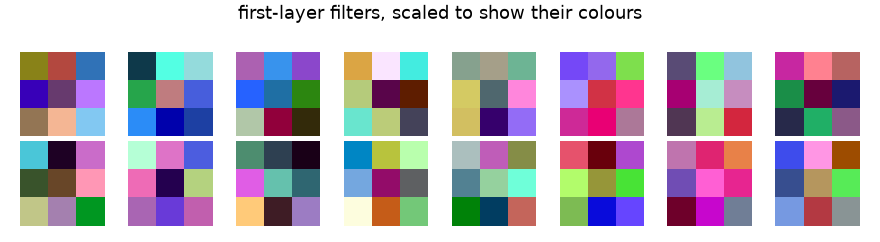

In [ ]:
from IPython.display import Image
Image('outputs/filters.png')

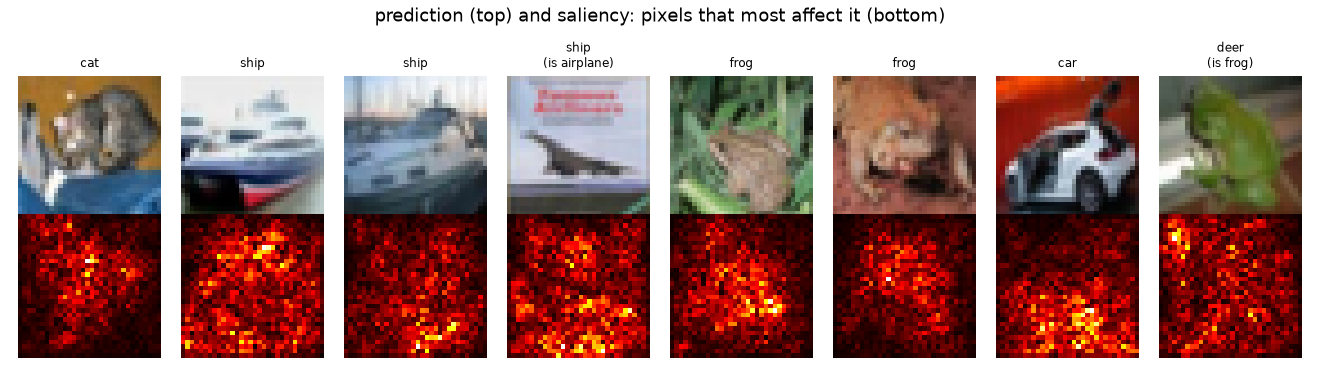

In [ ]:
from IPython.display import Image
Image('outputs/saliency.png')

Be honest about what you see:

- **The filters are hard to read.** With only 3 × 3 pixels each, there's little room for a clear pattern; the striking
  edge and colour detectors usually shown in books come from networks with much larger first-layer filters, trained on
  much larger images. You can still see colour-opponent patterns (a colour on one side, its opposite on the other).
- **The saliency maps are noisy.** Plain gradients jump from pixel to pixel. Some structure shows through (the car's body,
  the frogs), but the maps are a rough guide, not a precise explanation. Averaging the gradient over many slightly noisy
  copies of the image (SmoothGrad, see **Make it yours**) gives much cleaner maps.
- One of the "mistakes" is interesting: image 3 is labelled airplane, but it's a model plane on a printed sign, and the
  network says ship. A flat object in front of a pale background is exactly where the planes-vs-ships confusion of the
  last project lives.

## Step 2: the attack

The **fast gradient sign method** (FGSM) asks the opposite question: which tiny change to the image **increases the
loss** most? Take the gradient of the loss with respect to the pixels, keep only its sign, and move every pixel by ε in
that direction (section 10.3.4). One gradient step, no search, no access to anything but the model.

In [ ]:
%%writefile attack.py
"""Adversarial attacks (section 10.3.4): change every pixel by an invisible amount, in exactly the direction that
hurts the network most (the fast gradient sign method), and watch accuracy collapse."""
from pathlib import Path
import torch
import torch.nn.functional as F
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from data import load, normalize, CLASSES, MEAN, STD
from model import SmallCNN

saved = torch.load("cnn.pt")
model = SmallCNN(saved["width"]); model.load_state_dict(saved["state"]); model.eval()
X, y = load("test")
X, y = X[:2000], y[:2000]


def normalize_float(x01):
    """Like data.normalize, for images already scaled to [0, 1]."""
    return (x01 - MEAN) / STD


def fgsm(images_uint8, labels, eps):
    """Move each pixel by eps (out of 255) up or down, following the sign of the loss gradient."""
    x = (images_uint8.float() / 255).requires_grad_(True)
    F.cross_entropy(model(normalize_float(x)), labels).backward()
    return (x + eps / 255 * x.grad.sign()).clamp(0, 1).detach()


print(f"{'change per pixel':>17s} {'accuracy':>9s}")
for eps in [0, 1, 2, 4, 8]:
    adv = fgsm(X, y, eps) if eps else X.float() / 255
    with torch.no_grad():
        acc = (model(normalize_float(adv)).argmax(1) == y).float().mean().item()
    print(f"{eps:>13d}/255 {acc:9.3f}")

# Show one attacked image next to the original
Path("outputs").mkdir(exist_ok=True)
k = 6                                                   # a car the model classifies correctly
adv = fgsm(X[k:k + 1], y[k:k + 1], 4)
with torch.no_grad():
    before = CLASSES[model(normalize(X[k:k + 1])).argmax(1).item()]
    after = CLASSES[model(normalize_float(adv)).argmax(1).item()]
fig, axes = plt.subplots(1, 3, figsize=(7, 2.6))
axes[0].imshow(X[k].permute(1, 2, 0)); axes[0].set_title(f"original: {before}")
axes[1].imshow(adv[0].permute(1, 2, 0)); axes[1].set_title(f"attacked: {after}")
diff = (adv[0] - X[k].float() / 255)
axes[2].imshow(((diff - diff.min()) / (diff.max() - diff.min()).clamp(min=1e-8)).permute(1, 2, 0)); axes[2].set_title("the change, enlarged")
for ax in axes: ax.axis("off")
fig.tight_layout(); fig.savefig("outputs/attack.png", dpi=120)
print(f"\nimage {k}: '{before}' before the attack, '{after}' after changing each pixel by at most 4/255")

Writing attack.py


In [ ]:
!python attack.py

 change per pixel  accuracy
            0/255     0.800
            1/255     0.440
            2/255     0.228
            4/255     0.085
            8/255     0.045

image 6: 'car' before the attack, 'truck' after changing each pixel by at most 4/255


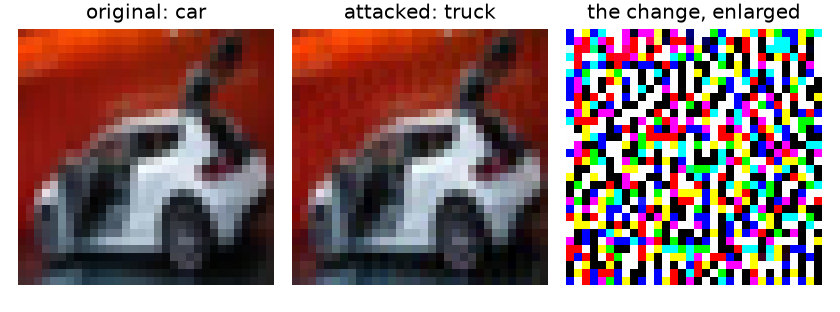

In [ ]:
from IPython.display import Image
Image('outputs/attack.png')

At ε = 1/255, the smallest change an 8-bit image can even store, accuracy falls from 0.80 to **0.44**. At 4/255 it's
0.085, worse than random guessing: the network isn't just confused, it's being steered to wrong answers. The attacked car
looks identical to the original; the change, enlarged on the right, looks like pure noise. But it isn't random: every
pixel moved in exactly the direction that hurts.

Why does it work so well? Each pixel's change is tiny, but there are 3,072 of them, all pushing the same way. Their
effects add up through the network. Section 10.3.4 describes this, and it applies to almost every network trained the
standard way, including very large ones.

## Step 3: write the README and publish

In [ ]:
%%writefile README.md
# Inside a CNN, and how to fool it

Opens up a CIFAR-10 convolutional network (79.6% test accuracy, PyTorch): its first-layer filters, gradient saliency
maps showing which pixels drive each prediction, and the fast gradient sign method (FGSM), an adversarial attack that
changes every pixel by an invisible amount and makes the network wrong.

![attack](outputs/attack.png)

## Results: FGSM on 2,000 test photos

| change per pixel (out of 255) | accuracy |
|---|---|
| 0 (original) | 0.800 |
| 1 | 0.440 |
| 2 | 0.228 |
| 4 | 0.085 |
| 8 | 0.045 |

A change of 1/255 per pixel, below what a screen can show, roughly halves the accuracy.

![saliency](outputs/saliency.png)

## Run it

```bash
pip install -r requirements.txt
python train.py --epochs 6    # or copy cnn.pt from the cifar-cnn project
python inspect_cnn.py         # filters and saliency maps
python attack.py              # FGSM attack
```

## What I learned

- The gradient of a class score with respect to the input pixels says which pixels matter, but plain gradients are noisy.
- The same gradient, used against the network, finds tiny changes that break it: accuracy 0.80 -> 0.09 at 4/255.
- High accuracy on normal data says nothing about robustness.

Based on section 10.3 of *Deep Learning: Foundations and Concepts* (Bishop & Bishop, 2024).

Writing README.md


```bash
git add .
git commit -m "CNN filters, saliency maps and FGSM adversarial attack"
git branch -M main
git remote add origin git@github.com:YOUR-USERNAME/cnn-under-the-hood.git
git push -u origin main
```

## Make it yours

- **SmoothGrad.** Average the saliency map over 30 copies of the image with a little Gaussian noise added. Are the maps
  clearer?
- **Adversarial training.** Train a new network where half of each mini-batch is FGSM-attacked images (with their true
  labels). How much clean accuracy does it lose, and how much robustness does it gain at ε = 2/255?
- **A targeted attack.** Instead of "any wrong class", push every image towards one chosen class (for example "frog") by
  descending the loss for that class. How often does it work?
- **Attack transfer.** Train a second network with a different seed. Do images attacked against the first also fool the
  second?

## On your CV

> **CNN interpretability and adversarial attacks** (PyTorch): saliency maps and filter visualization for a CIFAR-10 CNN;
> implemented FGSM, showing accuracy falling from 80.0% to 44.0% at 1/255 pixel change and 8.5% at 4/255.
> github.com/YOUR-USERNAME/cnn-under-the-hood

## Check yourself

- [ ] You can explain how a saliency map is computed, and why it's one backward pass.
- [ ] You can explain why FGSM uses only the sign of the gradient.
- [ ] You can explain why thousands of tiny changes can flip a prediction.